# CPF Week 4 Bridge Capstone — Covariance Geometry

## SPY and GLD: Joint Risk, Diversification, and Minimum-Variance Allocation

I examine the covariance structure of SPY and GLD using historical daily price data from the TPQ CPF Bridge companion repository.

I use daily returns to measure the joint variation of the two assets and then analyze that relationship through the sample covariance matrix, correlation, eigenvalues, eigenvectors, and the geometry of the return distribution.

I also examine how the estimated covariance structure affects portfolio variance across different SPY and GLD weights. The final allocation analysis focuses on the implications for a hypothetical risk-averse investor.

## Capstone Objective

My objective is to determine how the historical co-movement between SPY and GLD affects diversification and portfolio risk.

SPY provides broad exposure to the U.S. equity market, while GLD provides exposure to gold. I selected two economically different assets so that I can examine whether their historical return relationship provides meaningful diversification rather than assuming that diversification exists simply because the assets belong to different markets.

I focus on four questions:

1. How strongly did SPY and GLD move together during the selected sample period?
2. What does their sample covariance matrix indicate about their joint risk?
3. How do the eigenvalues, eigenvectors, return cloud, and covariance ellipse describe that joint risk geometrically?
4. How does the covariance structure affect the portfolio weights that minimize variance?

The results are historical sample estimates. I therefore interpret the covariance matrix and resulting portfolio weights as characteristics of the selected period rather than as fixed properties of SPY and GLD or forecasts of their future behavior.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
np.set_printoptions(precision=6, suppress=True)

pd.set_option(
    "display.float_format",
    lambda x: f"{x:.6f}"
)

In [3]:
ASSETS = ["SPY", "GLD"]

START_DATE = "2020-11-30"
END_DATE = "2025-11-28"

DATA_URL = (
    "https://raw.githubusercontent.com/"
    "yhilpisch/cpfbridge/main/markets/data/eoddata.csv"
)

print("Assets:", ASSETS)
print("Sample window:", START_DATE, "to", END_DATE)

Assets: ['SPY', 'GLD']
Sample window: 2020-11-30 to 2025-11-28


## Data and Methodology

I use end-of-day price levels for SPY and GLD from the TPQ CPF Bridge companion repository. My sample runs from November 30, 2020 through November 28, 2025.

I first load the full companion dataset and then restrict it to the two selected assets and the specified sample period. Before calculating returns, I verify that the observations are chronologically ordered, contain no missing values, and are strictly positive.

I convert the price series to daily log returns using

$$
r_{i,t}
=
\ln\left(
\frac{P_{i,t}}{P_{i,t-1}}
\right).
$$

I use returns rather than price levels because my objective is to measure the joint variation of day-to-day asset movements. Comparing absolute price levels would not provide the same measure of return risk and would also reflect differences in the numerical price scales of SPY and GLD.

From the aligned return observations, I estimate the sample covariance and correlation matrices. I then decompose the covariance matrix into its eigenvalues and eigenvectors to identify the principal directions and magnitudes of joint variation.

Finally, I examine how the covariance structure affects portfolio risk across different SPY and GLD weights. I use a long-only, fully invested allocation as the basis for my recommendation for a hypothetical risk-averse investor.

In [4]:
prices_raw = pd.read_csv(
    DATA_URL,
    parse_dates=["Date"],
    index_col="Date"
)

In [5]:
print("Shape:", prices_raw.shape)

print(
    "Date range:",
    prices_raw.index.min(),
    "to",
    prices_raw.index.max()
)

print("\nColumns:")
print(prices_raw.columns.tolist())

Shape: (2515, 8)
Date range: 2015-11-30 00:00:00 to 2025-11-28 00:00:00

Columns:
['AAPL', 'NVDA', 'JPM', 'SPY', 'GLD', 'TLT', 'EURUSD', 'BTC-USD']


In [6]:
prices = (
    prices_raw
    .loc[START_DATE:END_DATE, ASSETS]
    .copy()
)

print("Selected shape:", prices.shape)
print(
    "Selected date range:",
    prices.index.min(),
    "to",
    prices.index.max()
)

print("\nMissing values:")
print(prices.isna().sum())

Selected shape: (1256, 2)
Selected date range: 2020-11-30 00:00:00 to 2025-11-28 00:00:00

Missing values:
SPY    0
GLD    0
dtype: int64


In [7]:
print("First five selected observations:")
display(prices.head())

print("\nLast five selected observations:")
display(prices.tail())

print("\nMinimum observed prices:")
print(prices.min())

First five selected observations:


,SPY,GLD
Date,,
2020-11-30,337.529100,166.670000
2020-12-01,341.220700,170.180000
2020-12-02,341.938600,171.460000
2020-12-03,341.845400,172.810000
2020-12-04,344.791200,172.320000



Last five selected observations:


,SPY,GLD
Date,,
2025-11-21,659.030000,374.270000
2025-11-24,668.730000,380.200000
2025-11-25,675.020000,380.080000
2025-11-26,679.680000,383.120000
2025-11-28,683.390000,387.880000



Minimum observed prices:
SPY   337.529100
GLD   151.230000
dtype: float64


In [8]:
assert list(prices.columns) == ASSETS
assert len(prices) > 0
assert prices.index.is_monotonic_increasing
assert not prices.isna().any().any()
assert (prices > 0).all().all()

print("Data validation: PASS")
print("Number of aligned price observations:", len(prices))

Data validation: PASS
Number of aligned price observations: 1256


## Return Construction

I calculate daily log returns for SPY and GLD from the aligned price observations.

For asset $i$, the log return from date $t-1$ to date $t$ is

$$
r_{i,t}
=
\ln\left(
\frac{P_{i,t}}{P_{i,t-1}}
\right).
$$

Each return therefore requires two consecutive price observations. With 1,256 aligned price observations, the resulting return sample should contain 1,255 observations.

I use the return series as the basis for all subsequent estimates of volatility, covariance, correlation, covariance geometry, and portfolio variance.

In [9]:
log_returns = np.log(
    prices / prices.shift(1)
).dropna()

print("Return shape:", log_returns.shape)

print(
    "Return date range:",
    log_returns.index.min(),
    "to",
    log_returns.index.max()
)

print("\nMissing returns:")
print(log_returns.isna().sum())

print("\nFirst five return observations:")
display(log_returns.head())

Return shape: (1255, 2)
Return date range: 2020-12-01 00:00:00 to 2025-11-28 00:00:00

Missing returns:
SPY    0
GLD    0
dtype: int64

First five return observations:


,SPY,GLD
Date,,
2020-12-01,0.010878,0.020841
2020-12-02,0.002102,0.007493
2020-12-03,-0.000273,0.007843
2020-12-04,0.008580,-0.002840
2020-12-07,-0.002057,0.014804


In [10]:
assert list(log_returns.columns) == ASSETS
assert len(log_returns) == len(prices) - 1
assert log_returns.index.is_monotonic_increasing
assert not log_returns.isna().any().any()
assert np.isfinite(log_returns.to_numpy()).all()

print("Return validation: PASS")
print("Number of return observations:", len(log_returns))

Return validation: PASS
Number of return observations: 1255


## Sample Covariance Matrix

I estimate the sample covariance matrix from the 1,255 aligned daily log-return observations.

For SPY and GLD, the sample covariance is

$$
s_{\mathrm{SPY,GLD}}
=
\frac{1}{n-1}
\sum_{t=1}^{n}
\left(
r_{\mathrm{SPY},t}-\bar{r}_{\mathrm{SPY}}
\right)
\left(
r_{\mathrm{GLD},t}-\bar{r}_{\mathrm{GLD}}
\right).
$$

The resulting covariance matrix has the form

$$
\Sigma
=
\begin{pmatrix}
s_{\mathrm{SPY}}^2 & s_{\mathrm{SPY,GLD}} \\
s_{\mathrm{SPY,GLD}} & s_{\mathrm{GLD}}^2
\end{pmatrix}.
$$

The diagonal entries are the sample variances of SPY and GLD, while the off-diagonal entries measure how their daily log returns varied together during the sample period.

In [11]:
cov_matrix = log_returns.cov()

print("Sample Covariance Matrix:")
display(cov_matrix)

Sample Covariance Matrix:


,SPY,GLD
SPY,0.000116,0.000013
GLD,0.000013,0.000096


### Interpretation

The estimated daily log-return covariance matrix is approximately

$$
\Sigma
=
\begin{pmatrix}
0.000116 & 0.000013 \\
0.000013 & 0.000096
\end{pmatrix}.
$$

The diagonal entries show that SPY had the higher sample variance over the selected period, with a daily log-return variance of approximately $0.000116$, compared with approximately $0.000096$ for GLD.

The off-diagonal covariance is positive, at approximately $0.000013$. This indicates that SPY and GLD tended, on average, to move in the same direction rather than in opposite directions during the sample period.

The covariance is small relative to the individual variances, but covariance is scale-dependent, so I do not use its magnitude alone to judge the strength of the relationship. I examine correlation separately when assessing the diversification effect between the two assets.

## Return Cloud and Variance Ellipse

I next visualize the joint daily log returns of SPY and GLD. Each point in the return cloud represents one trading day, with the SPY return on one axis and the GLD return on the other.

I use the sample covariance matrix to construct the corresponding variance ellipse. The ellipse is centered at the sample mean return vector and summarizes the main directions of variation in the two-dimensional return data.

The eigenvectors of the covariance matrix determine the orientation of the ellipse, while the square roots of the corresponding eigenvalues determine the lengths of its principal semi-axes.

For covariance matrix $\Sigma$, the eigendecomposition is

$$
\Sigma v_i = \lambda_i v_i,
$$

where $\lambda_i$ is an eigenvalue and $v_i$ is its corresponding eigenvector.

I use these quantities only to construct and interpret the covariance ellipse required for the capstone.

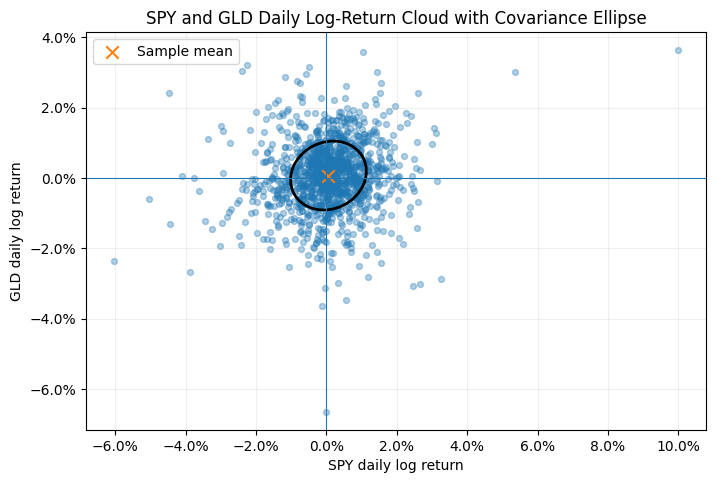

In [12]:
from matplotlib.patches import Ellipse
from matplotlib.ticker import PercentFormatter

# Sample mean vector
mean_vector = log_returns.mean().to_numpy()

# Eigenvalues and eigenvectors of the covariance matrix
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix.to_numpy())

# Sort from largest to smallest eigenvalue
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

# Orientation of the first principal axis
angle = np.degrees(
    np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0])
)

# Radius-1 covariance ellipse
width = 2 * np.sqrt(eigenvalues[0])
height = 2 * np.sqrt(eigenvalues[1])

fig, ax = plt.subplots(figsize=(8, 7))

ax.scatter(
    log_returns["SPY"],
    log_returns["GLD"],
    alpha=0.35,
    s=18
)

ellipse = Ellipse(
    xy=mean_vector,
    width=width,
    height=height,
    angle=angle,
    fill=False,
    linewidth=2
)

ax.add_patch(ellipse)

ax.scatter(
    mean_vector[0],
    mean_vector[1],
    marker="x",
    s=80,
    label="Sample mean"
)

ax.set_title(
    "SPY and GLD Daily Log-Return Cloud with Covariance Ellipse"
)
ax.set_xlabel("SPY daily log return")
ax.set_ylabel("GLD daily log return")

ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))

ax.axhline(0, linewidth=0.8)
ax.axvline(0, linewidth=0.8)

# Preserve the geometric meaning of the covariance ellipse
ax.set_aspect("equal", adjustable="box")

ax.legend()
ax.grid(alpha=0.2)

plt.show()

### Interpretation

The return cloud is concentrated around the sample mean, which lies close to zero on both axes. The observations are dispersed in both the SPY and GLD directions, with several larger return movements appearing outside the central cluster.

The covariance ellipse is slightly tilted upward from left to right. This orientation is consistent with the positive sample covariance estimated earlier and indicates that SPY and GLD exhibited some tendency to move in the same direction over the sample period.

The ellipse is wider in the SPY direction than in the GLD direction, which is consistent with the higher sample variance estimated for SPY. Its relatively modest diagonal tilt also suggests that the joint variation between the two assets is limited compared with their individual variation.

The ellipse summarizes the central covariance geometry of the return data. It does not imply that all observations should fall inside the ellipse, and the larger observations visible outside it remain part of the historical return distribution.

## Correlation and Diversification

I next calculate the sample correlation between SPY and GLD to assess the strength of their historical linear relationship.

The sample correlation is

$$
\rho_{\mathrm{SPY,GLD}}
=
\frac{
s_{\mathrm{SPY,GLD}}
}{
s_{\mathrm{SPY}}s_{\mathrm{GLD}}
}.
$$

Unlike covariance, correlation is standardized and therefore does not depend on the scale of the two return series. It ranges from $-1$ to $1$, with the sign indicating the direction of co-movement and the magnitude indicating the strength of the linear relationship.

I use the estimated correlation to evaluate the diversification effect of combining SPY and GLD over the selected sample period.

In [13]:
corr_matrix = log_returns.corr()

print("Sample Correlation Matrix:")
display(corr_matrix)

Sample Correlation Matrix:


,SPY,GLD
SPY,1.000000,0.125056
GLD,0.125056,1.000000


### Interpretation

The sample correlation between SPY and GLD is approximately

$$
\rho_{\mathrm{SPY,GLD}} = 0.1251.
$$

This is a positive but weak correlation. Over the selected sample period, SPY and GLD therefore showed only a limited tendency to move in the same direction on the same day.

For diversification, the important point is that the correlation is well below $1$. The two assets did not move together closely, so combining them can reduce portfolio risk compared with holding two assets whose returns are strongly positively correlated.

The correlation is not negative, so SPY and GLD did not systematically move in opposite directions. The diversification benefit comes instead from their relatively weak historical co-movement.

## Risk-Averse Allocation

For the allocation analysis, I assume a fully invested, long-only portfolio consisting only of SPY and GLD. If $w$ is the portfolio weight in SPY, then the weight in GLD is $1-w$, with

$$
0 \leq w \leq 1.
$$

The portfolio variance is

$$
\sigma_p^2
=
w^2\sigma_{\mathrm{SPY}}^2
+
(1-w)^2\sigma_{\mathrm{GLD}}^2
+
2w(1-w)\sigma_{\mathrm{SPY,GLD}}.
$$

Because the hypothetical investor is risk-averse, I use the allocation that minimizes estimated portfolio variance within the long-only feasible range.

For two assets, the unconstrained minimum-variance weight in SPY is

$$
w^*
=
\frac{
\sigma_{\mathrm{GLD}}^2-\sigma_{\mathrm{SPY,GLD}}
}{
\sigma_{\mathrm{SPY}}^2+\sigma_{\mathrm{GLD}}^2
-2\sigma_{\mathrm{SPY,GLD}}
}.
$$

I then check whether this weight lies between $0$ and $1$. If it does, it is also the long-only minimum-variance allocation.

In [14]:
var_spy = cov_matrix.loc["SPY", "SPY"]
var_gld = cov_matrix.loc["GLD", "GLD"]
cov_spy_gld = cov_matrix.loc["SPY", "GLD"]

w_spy_unconstrained = (
    (var_gld - cov_spy_gld)
    /
    (var_spy + var_gld - 2 * cov_spy_gld)
)

# Enforce the long-only constraint
w_spy = np.clip(w_spy_unconstrained, 0.0, 1.0)
w_gld = 1.0 - w_spy

min_variance = (
    w_spy**2 * var_spy
    + w_gld**2 * var_gld
    + 2 * w_spy * w_gld * cov_spy_gld
)

print(f"SPY weight: {w_spy:.4f}")
print(f"GLD weight: {w_gld:.4f}")
print(f"Minimum daily portfolio variance: {min_variance:.8f}")

SPY weight: 0.4463
GLD weight: 0.5537
Minimum daily portfolio variance: 0.00005903


### Allocation Recommendation

For a hypothetical risk-averse investor, I would allocate approximately **44.63% to SPY and 55.37% to GLD** based on the minimum-variance portfolio estimated from the sample covariance matrix.

This allocation produces an estimated minimum daily portfolio variance of approximately

$$
0.00005903.
$$

The portfolio assigns slightly more weight to GLD because GLD had the lower individual return variance over the sample period. At the same time, the weak positive correlation between SPY and GLD allows the portfolio to benefit from diversification because the two assets did not move closely together.

The recommended weights therefore reflect both the individual risk of each asset and their covariance. The allocation is based only on historical sample risk and does not incorporate expected returns or assume that the estimated covariance structure will remain unchanged in the future.

## Final Validation

I finish by validating the calculations used in the four capstone requirements. These checks confirm that the selected return data are valid, the covariance and correlation calculations are internally consistent, the covariance ellipse is based on a valid covariance matrix, and the recommended portfolio satisfies the long-only, fully invested constraint.

In [15]:
# 1. Return data validation
assert list(log_returns.columns) == ["SPY", "GLD"]
assert len(log_returns) > 0
assert not log_returns.isna().any().any()
assert np.isfinite(log_returns.to_numpy()).all()

print("PASS 1 — Return data are valid and aligned.")


# 2. Sample covariance validation
assert cov_matrix.shape == (2, 2)
assert np.allclose(cov_matrix, cov_matrix.T)
assert np.isfinite(cov_matrix.to_numpy()).all()

cov_eigenvalues = np.linalg.eigvalsh(cov_matrix.to_numpy())
assert np.all(cov_eigenvalues >= -1e-12)

print("PASS 2 — Sample covariance matrix is finite, symmetric, and positive semidefinite.")


# 3. Correlation validation
assert corr_matrix.shape == (2, 2)
assert np.allclose(corr_matrix, corr_matrix.T)
assert np.allclose(np.diag(corr_matrix), 1.0)

rho_spy_gld = corr_matrix.loc["SPY", "GLD"]
assert -1.0 <= rho_spy_gld <= 1.0

print("PASS 3 — Sample correlation matrix is internally consistent.")


# 4. Variance-ellipse validation
assert np.all(np.isfinite(eigenvalues))
assert np.all(eigenvalues >= 0)
assert np.all(np.isfinite(eigenvectors))

print("PASS 4 — Covariance ellipse inputs are valid.")


# 5. Portfolio-weight validation
assert 0.0 <= w_spy <= 1.0
assert 0.0 <= w_gld <= 1.0
assert np.isclose(w_spy + w_gld, 1.0)

print("PASS 5 — Portfolio weights are long-only and fully invested.")


# 6. Minimum-variance validation
assert min_variance >= 0
assert min_variance <= var_spy + 1e-12
assert min_variance <= var_gld + 1e-12

print("PASS 6 — Recommended portfolio variance is below either single-asset variance.")


print("\nALL CAPSTONE VALIDATION CHECKS PASSED.")

PASS 1 — Return data are valid and aligned.
PASS 2 — Sample covariance matrix is finite, symmetric, and positive semidefinite.
PASS 3 — Sample correlation matrix is internally consistent.
PASS 4 — Covariance ellipse inputs are valid.
PASS 5 — Portfolio weights are long-only and fully invested.
PASS 6 — Recommended portfolio variance is below either single-asset variance.

ALL CAPSTONE VALIDATION CHECKS PASSED.
